<a href="https://colab.research.google.com/github/youssefouabir-lab/Introduction_to_ai/blob/main/LESSON_8_ASSIGNMENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lesson 8 assignment**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay
)

In [4]:
# 1. Create dataset & preprocess (cleaning, encoding, split, scaling)
X, y = make_classification(
    n_samples=3000, n_features=6, n_informative=4, n_redundant=1,
    weights=[0.85, 0.15], random_state=42
)
cols = ['tx_amount', 'distance_km', 'tx_hour', 'velocity_24h', 'acct_age_yr', 'channel_code']
df = pd.DataFrame(X, columns=cols)
df['channel'] = np.where(df['channel_code'] > 0, 'online', 'branch_pos')
df.drop(columns=['channel_code'], inplace=True)
df['is_fraud'] = y

In [5]:
# Remove duplicates and handle any missing values
df = df.drop_duplicates().fillna(df.median(numeric_only=True))

In [6]:
# Encode categorical feature
df = pd.get_dummies(df, columns=['channel'], drop_first=True)

X_data = df.drop(columns=['is_fraud'])
y_data = df['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, stratify=y_data, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Class balance:
 is_fraud
0    0.847
1    0.153
Name: proportion, dtype: float64


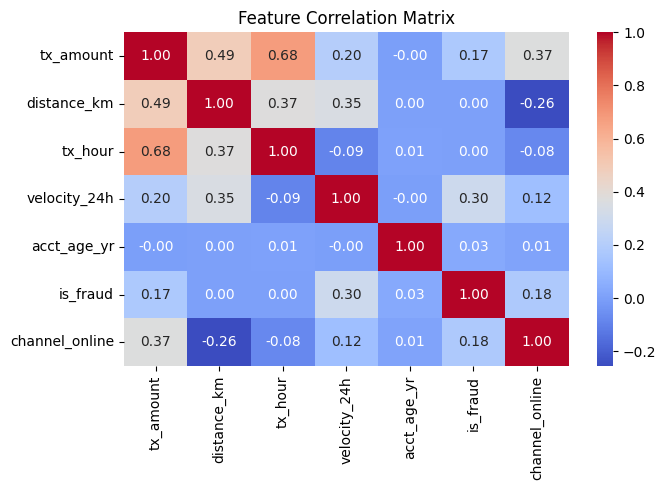


--- Logistic Regression ---
Accuracy : 0.872
Precision: 0.778
Recall   : 0.228
F1-Score : 0.353
ROC-AUC  : 0.702

--- Random Forest ---
Accuracy : 0.945
Precision: 0.915
Recall   : 0.707
F1-Score : 0.798
ROC-AUC  : 0.945


In [7]:
# 2. Exploratory Data Analysis (EDA)
print("Class balance:\n", y_data.value_counts(normalize=True).round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

# 3. Train & evaluate two classification models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

for name, model in models.items():
    # Use scaled features for Logistic Regression; raw features work fine for tree models
    X_tr = X_train_scaled if name == "Logistic Regression" else X_train
    X_te = X_test_scaled if name == "Logistic Regression" else X_test

    model.fit(X_tr, y_train)
    preds = model.predict(X_te)
    probs = model.predict_proba(X_te)[:, 1]

    print(f"\n--- {name} ---")
    print(f"Accuracy : {accuracy_score(y_test, preds):.3f}")
    print(f"Precision: {precision_score(y_test, preds):.3f}")
    print(f"Recall   : {recall_score(y_test, preds):.3f}")
    print(f"F1-Score : {f1_score(y_test, preds):.3f}")
    print(f"ROC-AUC  : {roc_auc_score(y_test, probs):.3f}")

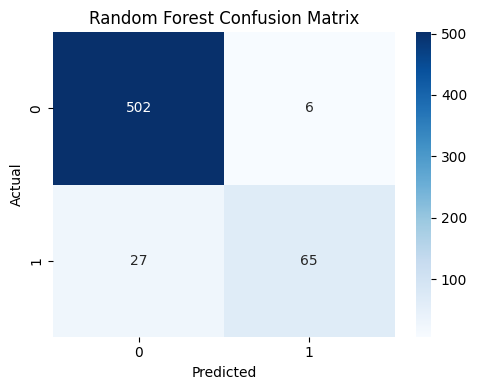

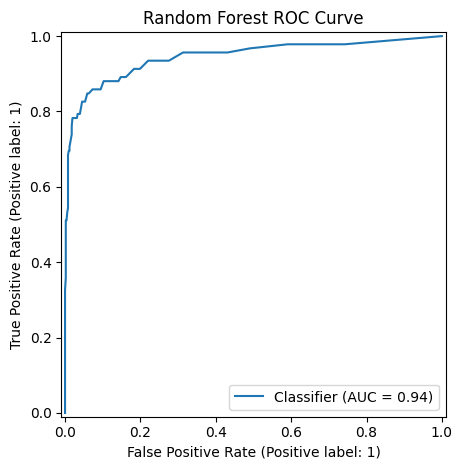

In [8]:
# 4. Confusion matrix & ROC curve for best model (Random Forest)
rf = models["Random Forest"]
rf_preds = rf.predict(X_test)
rf_probs = rf.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, rf_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, rf_probs)
plt.title("Random Forest ROC Curve")
plt.tight_layout()
plt.show()

**Deployment & Monitoring Notes**

Deployment method: Package the trained model and preprocessing pipeline (using joblib or pickle) inside a lightweight REST API (such as FastAPI or Flask) hosted in a container. Incoming transactions send feature values in JSON and receive a fraud probability score in milliseconds.

Operational issues & real-time data: Missing fields, unexpected categories, schema mismatches, or API latency spikes can break scoring or delay card approvals. Validate incoming payloads before scoring, apply safe fallback rules/defaults when a non-critical field is missing, and set strict timeout thresholds.

Ongoing monitoring & maintenance: Track model latency, error rates, prediction drift (shifts in flagged volume), and feature drift (changes in transaction amounts or channels). Re-evaluate against confirmed chargebacks/investigations on a regular schedule and retrain when performance degrades.

